In [3]:
# conda env 'at3d'

import pymap3d as pm
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import at3d
import netCDF4 as nc
import os
from scipy.interpolate import griddata

In [4]:
rte_grid_title = 'default'
rte_grid_file = '../data/RTG_{}.nc'.format(rte_grid_title)
rte_grid = xr.load_dataset(rte_grid_file)

region_title = 'CAMP2Ex_RF17_A'
cth_file = '../data/MISR_CTH_{}.nc'.format(region_title)
cloud_data = xr.load_dataset(cth_file)

carving_title = 'cloudy'
carved_vol_file = '../data/CARVED_VOL_{}_RTG_{}_SC_{}.nc'.format(region_title, rte_grid_title, carving_title)
carved_volume = xr.load_dataset(carved_vol_file)

lcl = 0.4
lcl_str = '{:.3f}'.format(lcl).replace('.','p')

out_file = '../data/CVM_{}_RTG_{}_SC_{}_LCL{}.nc'.format(region_title, rte_grid_title, carving_title, lcl_str)

In [5]:
wgs84 = pm.Ellipsoid('wgs84')
e, n, u = pm.geodetic2enu(
    cloud_data.lat1100.data,
    cloud_data.lon1100.data,
    cloud_data.cth.data,
    cloud_data.center_lat.data,
    cloud_data.center_lon.data,
    0.0,
    ell=wgs84,
    deg=True
)
cloud_data['E'] = (['y1100', 'x1100'], e/1000)
cloud_data['N'] = (['y1100', 'x1100'], n/1000)
cloud_data['z_cloud'] = (['y1100', 'x1100'], u/1000)

# Horizontal shift to place origin at the corner of the rte grid (maintain centering)
cloud_data['E'] = cloud_data.E + np.max(rte_grid.x.data)/2
cloud_data['E'] = cloud_data.E.assign_attrs(units='km')
cloud_data['N'] = cloud_data.N + np.max(rte_grid.y.data)/2
cloud_data['N'] = cloud_data.N.assign_attrs(units='km')

In [6]:
# Create the new grid
grid_x, grid_y = np.meshgrid(rte_grid.x.data, rte_grid.y.data, indexing='ij')

# Flatten the original grid and data
points = np.array([cloud_data.E.data.flatten(), cloud_data.N.data.flatten()]).T
values = cloud_data.z_cloud.data.flatten()

# Mask out NaN values
mask = ~np.isnan(values)
points = points[mask]
values = values[mask]

# Interpolate the data onto the new grid
cth_interp = griddata(points, values, (grid_x, grid_y), method='linear')

In [7]:
cth_on_rte_grid = rte_grid.z.data[np.searchsorted(rte_grid.z.data, cth_interp, side='right')]

Text(0.5, 1.0, 'CTH on RTE Grid')

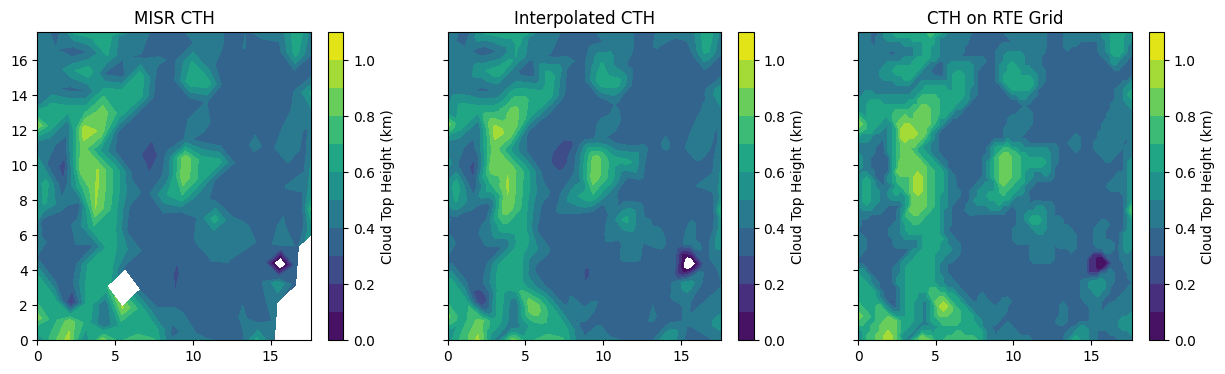

In [8]:
levels = np.arange(0, 1.2, 0.1)
f, ax = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
c0 = ax[0].contourf(cloud_data.E.data, cloud_data.N.data, cloud_data.z_cloud.data, levels=levels)
plt.colorbar(c0, ax=ax[0], label='Cloud Top Height (km)')
ax[0].set_title('MISR CTH')
c1 = ax[1].contourf(grid_x, grid_y, cth_interp, levels=levels)
plt.colorbar(c1, ax=ax[1], label='Cloud Top Height (km)')
ax[1].set_title('Interpolated CTH')
c2 = ax[2].contourf(grid_x, grid_y, cth_on_rte_grid, levels=levels)
plt.colorbar(c2, ax=ax[2], label='Cloud Top Height (km)')
ax[2].set_title('CTH on RTE Grid')

In [9]:
cth_on_rte_grid = np.expand_dims(cth_on_rte_grid, axis=-1)
cth_mask = (rte_grid.z.data <= cth_on_rte_grid).astype(int)
rte_grid['cth_mask'] = (['x', 'y', 'z'], cth_mask)

In [10]:
lcl_on_rte_grid = rte_grid.z.data[np.searchsorted(rte_grid.z.data, lcl, side='right') - 1]
lcl_mask = np.zeros((rte_grid.dims['x'], rte_grid.dims['y'], rte_grid.dims['z']))
lcl_mask[:,:,rte_grid.z.data >= lcl_on_rte_grid] = 1
rte_grid['lcl_mask'] = (['x', 'y', 'z'], lcl_mask)

In [11]:
rte_grid['carved_mask'] = (['x', 'y', 'z'], carved_volume.mask.data)

In [12]:
rbg_mask = np.zeros((rte_grid.dims['y'], rte_grid.dims['x'], rte_grid.dims['z'], 3))
rbg_mask[:,:,:,0] = rte_grid.cth_mask # Red
rbg_mask[:,:,:,1] = rte_grid.lcl_mask # Green
rbg_mask[:,:,:,2] = rte_grid.carved_mask # Blue
rte_grid['rbg_mask'] = (['x', 'y', 'z', 'rgb'], rbg_mask)

In [13]:
mask = np.logical_and(rte_grid.cth_mask.data, rte_grid.lcl_mask.data)
rte_grid['cloud_volume_mask'] = (['x', 'y', 'z'], mask)
rte_grid.to_netcdf(out_file)

In [14]:
rte_grid['cfba'] = rte_grid.cloud_volume_mask.sum(('x','y')) / (rte_grid.dims['x'] * rte_grid.dims['y'])

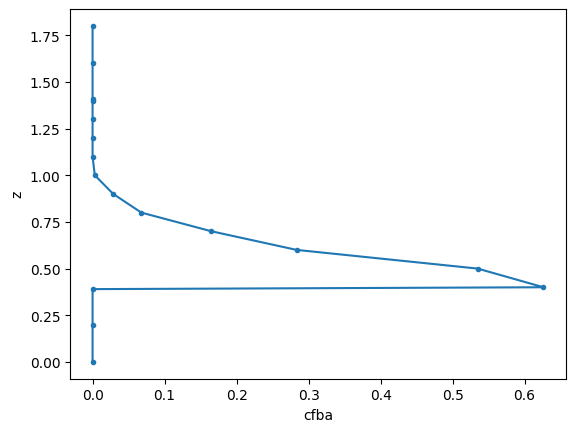

In [15]:
rte_grid.cfba.plot(y='z', marker='.')

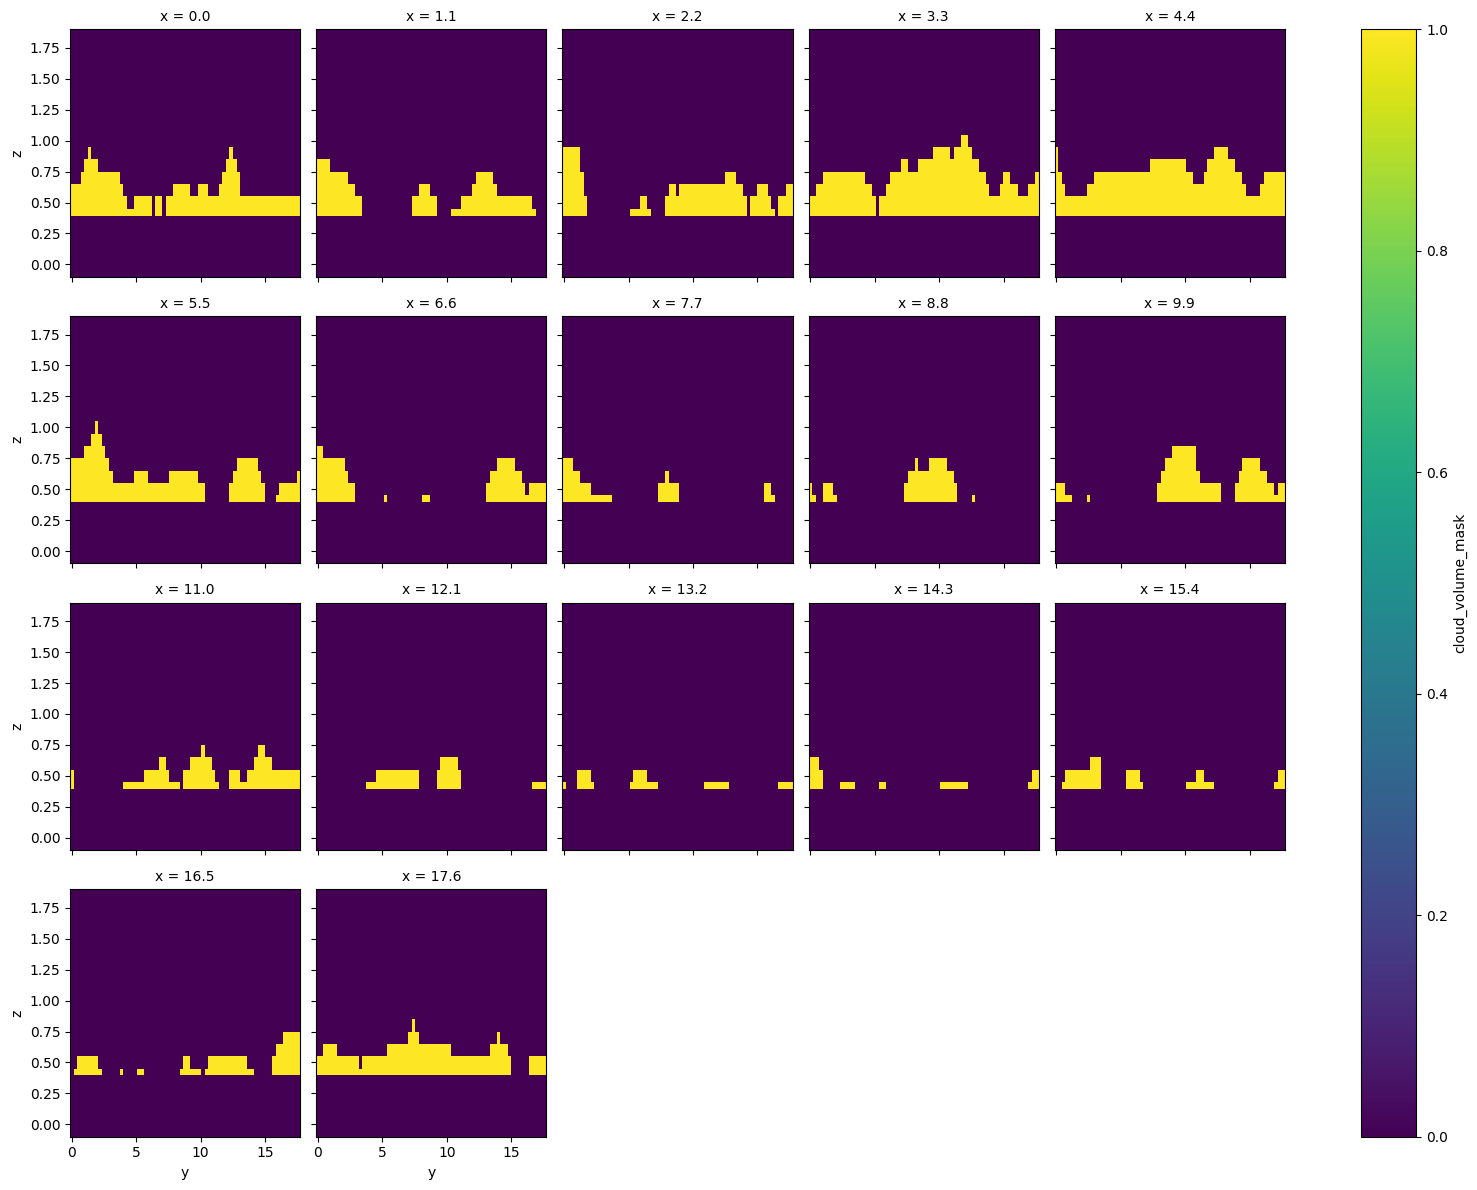

In [16]:
rte_grid.cloud_volume_mask.isel(x=slice(0,None,4)).plot(x='y', y='z', col='x', col_wrap=5)

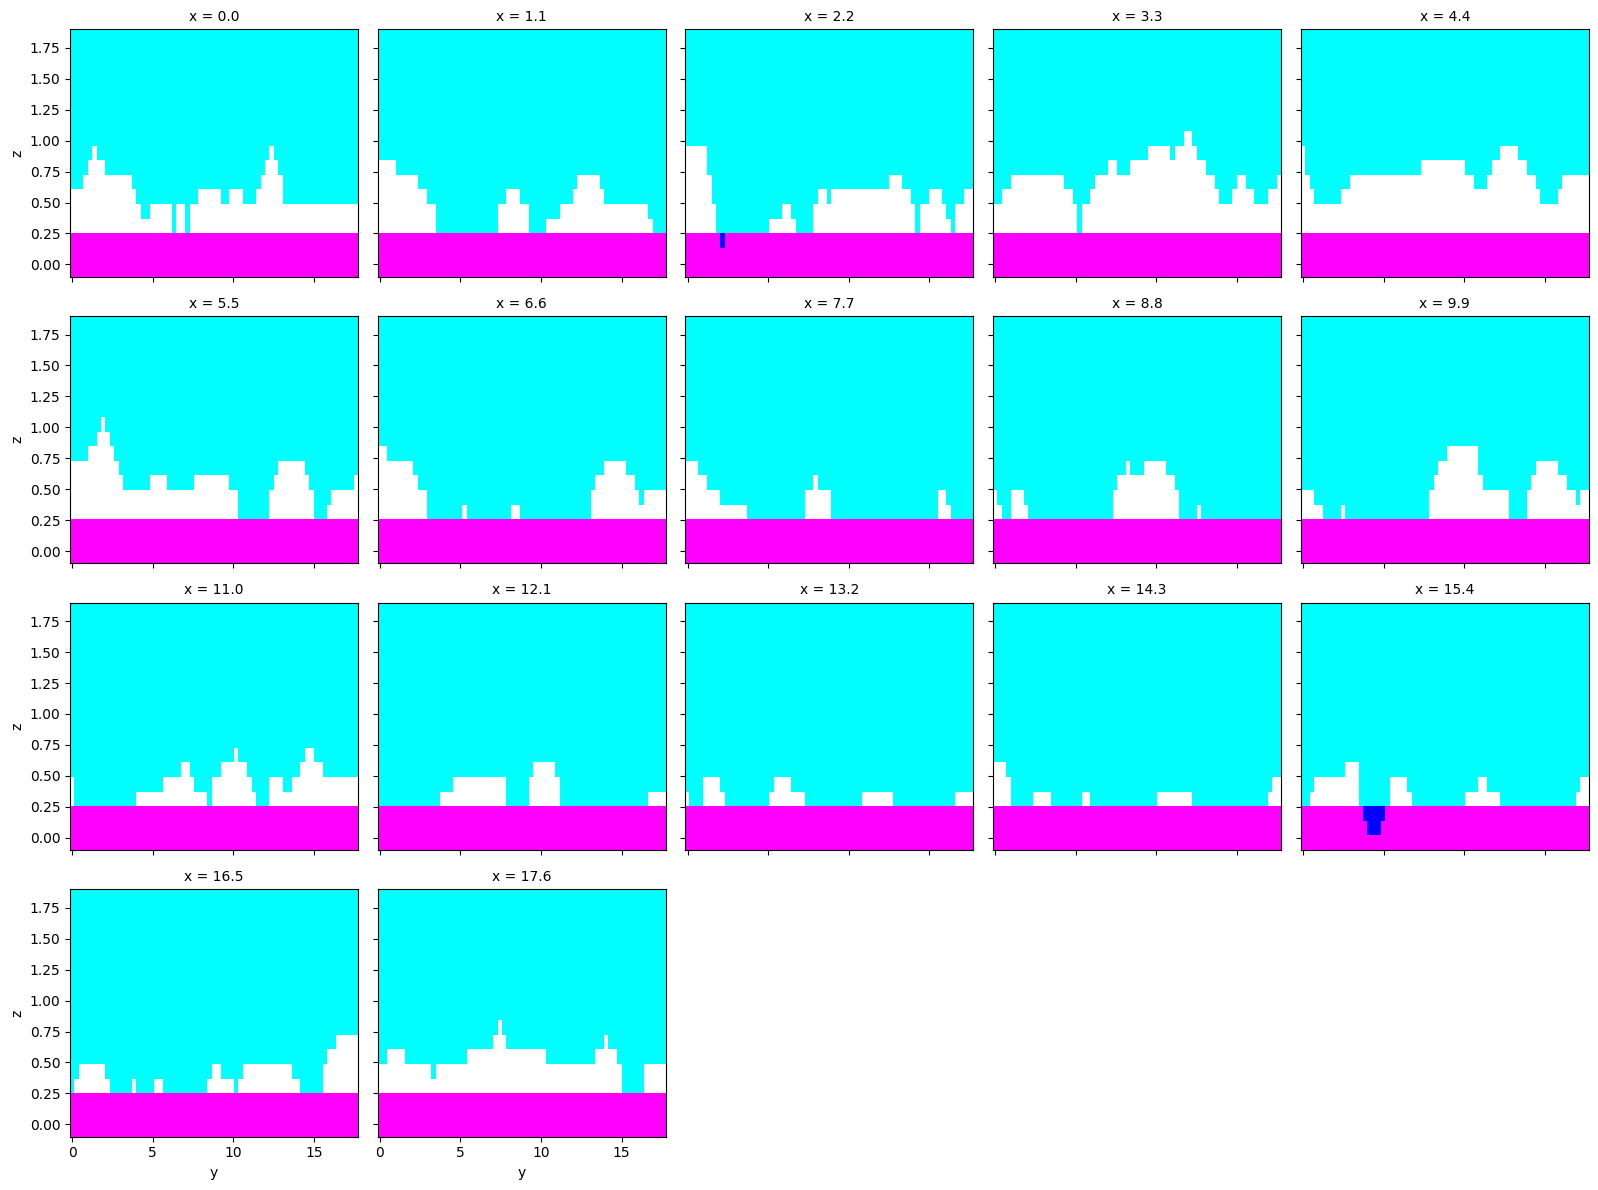

In [17]:
rte_grid.rbg_mask.isel(x=slice(0,None,4)).plot.imshow(x='y', y='z', col='x', col_wrap=5)